# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 03
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | First-order parent relations | 25 |
| Q2 | A* with an admissible heuristic | 30 |
| Q3 | Iris K-means model selection | 35 |
| Q4 | Viva: FOL, g/h/f, centroid, inertia, silhouette | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_03_A.py) | [Q2 / B](Set_03_B.py) | [Q3 / C](Set_03_C.py) | [Q4 / D: Viva practice](Set_03_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. First-Order Logic Representation (25 marks)
**Question specification**  
Given `Parent(Ali,Babu)`, `Parent(Ali,Rina)`, `Parent(Babu,Karim)`, `Parent(Rina,Sumi)`, `Parent(Karim,Nila)`, implement children, grandparent, and sibling queries, and display inferred relations.

### Theory and mathematical background
First-order logic models named **objects** and **relations**. For instance, $Parent(Ali,Babu)$ asserts a binary relation; `Ali` and `Babu` are constants, whereas $x,y,z$ are variables.

A grandparent inference rule is
$$\forall x\,\forall y\,\forall z:\quad Parent(x,y)\land Parent(y,z)\Rightarrow Grandparent(x,z).$$
A sibling relation uses a shared parent:
$$Sibling(x,y)\Leftarrow\exists p\, [Parent(p,x)\land Parent(p,y)\land x\ne y].$$
The implementation below demonstrates **specific relation inference over Python tuples**, not a general-purpose first-order theorem prover.

In [1]:
from itertools import combinations

def children_of(person, parents):
    return sorted({child for parent, child in parents if parent == person})

def grandparent_relations(parents):
    return sorted({(x, z) for x, y in parents for middle, z in parents if y == middle})

def siblings_relations(parents):
    result = set()
    for p in {person for person, child in parents}:
        children = children_of(p, parents)
        for x, y in combinations(children, 2):
            result.add((x, y))  # Canonical unordered pair: no duplicates/self-pairs.
    return sorted(result)

def print_relations(parents):
    people = sorted({x for pair in parents for x in pair})
    print('Parent facts:', sorted(parents))
    print('Children queries:')
    for name in people:
        kids = children_of(name, parents)
        if kids: print(f'  children_of({name}) = {kids}')
    print('Grandparent relations:', grandparent_relations(parents))
    print('Sibling relations (unordered):', siblings_relations(parents))

parents = {('Ali','Babu'),('Ali','Rina'),('Babu','Karim'),
           ('Rina','Sumi'),('Karim','Nila')}
print_relations(parents)
print('Example binding: Parent(Ali,Babu) and Parent(Babu,Karim) => Grandparent(Ali,Karim)')
assert ('Ali','Karim') in grandparent_relations(parents)
assert ('Babu','Rina') in siblings_relations(parents)


Parent facts: [('Ali', 'Babu'), ('Ali', 'Rina'), ('Babu', 'Karim'), ('Karim', 'Nila'), ('Rina', 'Sumi')]
Children queries:
  children_of(Ali) = ['Babu', 'Rina']
  children_of(Babu) = ['Karim']
  children_of(Karim) = ['Nila']
  children_of(Rina) = ['Sumi']
Grandparent relations: [('Ali', 'Karim'), ('Ali', 'Sumi'), ('Babu', 'Nila')]
Sibling relations (unordered): [('Babu', 'Rina')]
Example binding: Parent(Ali,Babu) and Parent(Babu,Karim) => Grandparent(Ali,Karim)


### Result interpretation and discussion
Tuple matching binds a common intermediate value $y$ in `Parent(x,y)` and `Parent(y,z)`. Siblings are printed as **unordered pairs** and exclude self-pairs. For example, `Babu` and `Rina` share parent `Ali`.

---
## Q2. A* Search (30 marks)
**Question specification**  
Directed weighted edges: `S-A=2, S-B=4, A-C=2, A-D=5, B-D=1, C-G=5, D-G=3`; `h(S,A,B,C,D,G)=(6,5,4,4,2,0)`. Print expansion trace with $g,h,f$, best path and total cost; rerun with all $h=0$.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

graph={'S':[('A',2),('B',4)],'A':[('C',2),('D',5)],
       'B':[('D',1)],'C':[('G',5)],'D':[('G',3)],'G':[]}
h={'S':6,'A':5,'B':4,'C':4,'D':2,'G':0}
path,cost,trace=astar(graph,h,'S','G')
display_astar_trace(trace)
print('A* path:',path,'| total cost:',cost)
h_zero={node:0 for node in h}
zero_path,zero_cost,zero_trace=astar(graph,h_zero,'S','G')
print('With h=0 (uniform-cost behavior):',zero_path,'| cost:',zero_cost)
display_astar_trace(zero_trace)
assert cost == zero_cost


Node     g(n)     h(n)     f(n)
   S        0        6        6
   A        2        5        7
   B        4        4        8
   D        5        2        7
   C        4        4        8
   G        8        0        8
A* path: ['S', 'B', 'D', 'G'] | total cost: 8
With h=0 (uniform-cost behavior): ['S', 'B', 'D', 'G'] | cost: 8
Node     g(n)     h(n)     f(n)
   S        0        0        0
   A        2        0        2
   B        4        0        4
   C        4        0        4
   D        5        0        5
   G        8        0        8


### Result interpretation and discussion
With $h(n)=0$, the A* priority becomes $f(n)=g(n)$, so it behaves like uniform-cost search on nonnegative edge costs. The true optimal cost here is 8 via `S→B→D→G` (4+1+3). Equal-cost alternate routes are possible; the tie-breaker determines which one is returned.

---
## Q3. K-means Clustering (35 marks)
**Question specification**  
Use the **first two Iris features**. Compare $k=2,3,4,5$ using inertia and silhouette, select a suitable $k$, and visualize the cluster assignments and centroids.

### Theory and mathematical background
**K-means** is an unsupervised clustering method that alternates assigning samples to the nearest centroid and updating centroids. For $K$ clusters, it seeks to minimize
$$J=\sum_{i=1}^{n}\left\|\mathbf x_i-\boldsymbol\mu_{z_i}\right\|_2^2.$$
`inertia_` is the final within-cluster sum of squares. The silhouette of a sample is
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},$$
where $a(i)$ is average within-cluster distance and $b(i)$ is its smallest mean distance to another cluster. Larger silhouette generally indicates better-separated clusters. **Cluster IDs are arbitrary** and are not species class labels.

Feature scaling changes the distance geometry and inertia's units; compare inertia only for models using comparable feature representations.

 k  inertia  silhouette
 2  58.2041      0.4630
 3  37.0507      0.4451
 4  27.9902      0.4249
 5  20.9968      0.4101
Selected k (highest silhouette among tested values): 2
Centroids (sepal length, sepal width):
 [[5.224 3.131]
 [6.61  2.966]]


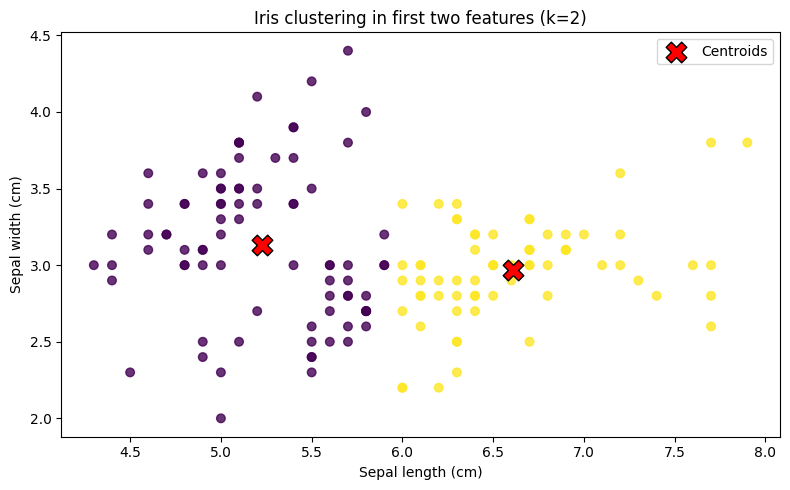

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()

X = iris.data[:, :2]  # sepal length and sepal width (cm)
rows, cluster_models = [], {}
for k in [2,3,4,5]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    score = silhouette_score(X,model.labels_)
    rows.append({'k':k,'inertia':model.inertia_,'silhouette':score})
    cluster_models[k]=model
table=pd.DataFrame(rows)
print(table.round(4).to_string(index=False))
selected_k=int(table.loc[table['silhouette'].idxmax(),'k'])
best=cluster_models[selected_k]
print('Selected k (highest silhouette among tested values):',selected_k)
print('Centroids (sepal length, sepal width):\n',best.cluster_centers_.round(3))
plt.figure(figsize=(8,5))
plt.scatter(X[:,0],X[:,1],c=best.labels_,alpha=.8,s=38,cmap='viridis')
plt.scatter(best.cluster_centers_[:,0],best.cluster_centers_[:,1],
            marker='X',s=220,c='red',edgecolors='black',label='Centroids')
plt.xlabel('Sepal length (cm)'); plt.ylabel('Sepal width (cm)')
plt.title(f'Iris clustering in first two features (k={selected_k})')
plt.legend(); plt.tight_layout(); plt.show()


### Result interpretation and discussion
The chosen $k$ follows a **defined criterion** (largest silhouette of the four candidates); other justified criteria can select a different $k$. A cluster labeled 0 is merely the first centroid index returned by K-means and is **not** Iris species class 0.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is a predicate? | A relation/property symbol such as Parent(x,y). |
| What is tuple matching? | Binding the same intermediate object across relation facts. |
| What is g(n)? | Accumulated path cost from the start. |
| What is h(n)? | Estimated remaining goal cost. |
| What is f(n)? | A* priority: g(n)+h(n). |
| What is a centroid? | Mean feature vector of a cluster. |
| What is inertia? | Sum of squared distances to assigned centroids. |
| What is silhouette? | Cluster cohesion-versus-separation score. |

| What is a constant in first-order logic? | A symbol naming a specific object, such as Ali or Rina. |
| What is a variable in first-order logic? | A placeholder, such as x or y, that may refer to different objects. |
| What does admissible mean for h(n)? | The estimate never exceeds the actual least remaining cost to the goal. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.